# 🧠 Vision AI 특강 정리 노트북
### Hugging Face CLI + Colab CLI로 "남의 GPU"에서 모델 추론·파인튜닝하기

| 항목 | 내용 |
|---|---|
| 실습 저장소 | [yblee110/vision-ai-notebook](https://github.com/yblee110/vision-ai-notebook) |
| 실습 목표 | 병·그릇·캔·컵·접시 **5가지 물체 분류** (사전학습 모델 DeiT-tiny를 가볍게 파인튜닝) |
| 사용 도구 | GitHub Codespaces · Hugging Face CLI(`hf`) · Google Colab CLI(`colab`) · Transformers · PyTorch |
| 핵심 한 줄 | **내 컴퓨터는 명령만 내리고, 무거운 연산은 Colab GPU가 한다** |

---

## 📌 목차
0. 내 소감 & 오늘 깨달은 것
1. 전체 그림 한 장으로 보기
2. Colab CLI란? (Colab 노트북과 비교)
3. 왜 Colab CLI인가? (컴퓨팅 유닛 · 비용 안전성)
4. Colab CLI 핵심 명령어
5. Hugging Face CLI와 revision 고정
6. 개발 환경: Fork → Codespaces
7. 실습 흐름: 00 · 01 · 02 노트북
8. 핵심 코드 4개 + pipeline() 읽기 (+ 코드 쉽게 읽기)
9. 파인튜닝 개념과 결과 (+ 직접 실행해 본 결과 이미지)
10. 셸 시연 & 에이전트 스킬
11. GPU 고르는 법 (Q&A)
12. 막혔던 점 & 트러블슈팅
13. 강사님 마무리 메시지 & 복습 체크리스트

> 💡 이 노트북의 **코드 셀은 GPU·추가 설치 없이 실행되는 개념 확인용 예제**입니다. 실제 Colab 명령은 실수로 실행되지 않도록 마크다운 안에만 적었습니다.

## 0. 내 소감 & 오늘 깨달은 것

### 😵 어려웠던 점: 마크다운(README)이 제대로 안 보였다
- Codespaces(VS Code)에서 `README.md`를 열면 **원본 텍스트(`#`, `|`, `**` 기호 그대로)** 로 보여서 안내를 따라가기 힘들었다.
- 강의 중에도 "마크다운 뷰로 바꾸는 방법을 찾아야 한다"는 얘기가 나왔다.

**✅ 해결법 (다음엔 이렇게!)**

| 방법 | 동작 |
|---|---|
| `Ctrl + Shift + V` | 현재 탭을 **미리보기(렌더링)** 로 열기 |
| `Ctrl + K` 다음 `V` | **옆 창에** 미리보기 열기 → 원본과 나란히 보면서 복사하기 좋음 |
| 탐색기에서 `.md` 우클릭 → **Open Preview** | 마우스로 열기 |
| 에디터 오른쪽 위 🔍(돋보기+문서) 아이콘 | 미리보기 토글 |

> 이 정리를 **`.ipynb` 노트북**으로 만든 이유도 같다. 노트북의 마크다운 셀은 열자마자 렌더링되어 보인다.

### 💡 깨달은 것: 왜 굳이 CLI를 쓰는가?
> **내 컴퓨터 자원(GPU·메모리)이 부족한데 모델을 돌리고 싶을 때** 쓰는 것이다.

- 내 PC / Codespaces(CPU 2코어·8GB)에는 GPU가 없다 → 모델 학습·추론이 불가능하거나 매우 느림.
- `colab` CLI는 **터미널 명령 몇 줄로 Colab의 GPU(T4 등)를 빌려와** 코드를 실행하고 결과만 다시 가져온다.
- 게다가 명령어로 되어 있으니 **반복 실행·자동화·AI 에이전트 연결**까지 가능하다. (→ 3장)

## 1. 전체 그림 한 장으로 보기

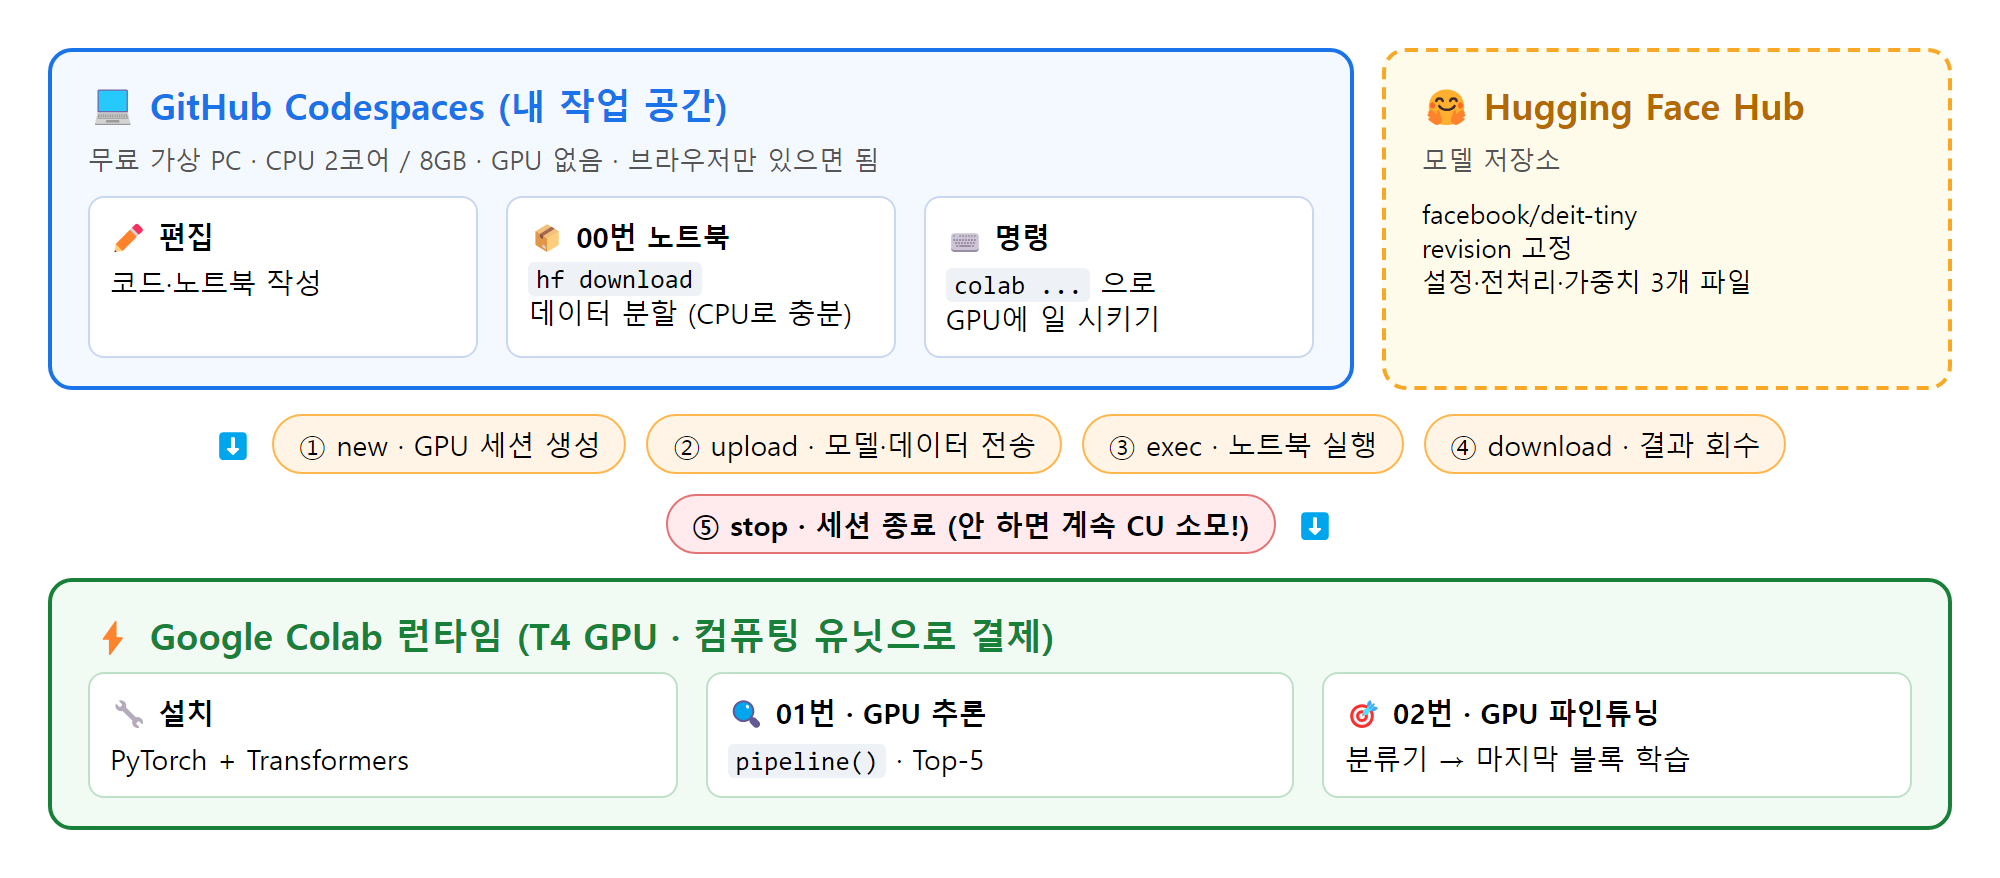

In [1]:
# 전체 구조: Codespaces에서 명령하고 Colab GPU가 연산
from IPython.display import Image
Image("images/architecture.png")

| 도구 | 하는 일 | 실행 위치 |
|---|---|---|
| `hf download` (Hugging Face CLI) | 원본 모델·전처리 설정 다운로드 | Codespaces |
| `colab` (Colab CLI) | GPU 생성·파일 전송·노트북 실행·회수·종료 | 명령은 Codespaces, **연산은 Colab** |
| Transformers | `pipeline()` 추론, 모델 구조·전처리 불러오기 | Colab GPU |
| PyTorch | GPU 연산, 손실·역전파·가중치 업데이트 | Colab GPU |
| NumPy·Pillow·PyArrow | 이미지 읽기, 데이터 분할 | Codespaces |

## 2. Colab CLI란?

> **CLI = Command Line Interface.** 마우스 대신 **터미널 명령어**로 프로그램을 다루는 방식.

**Colab CLI** = 터미널에서 Google Colab을 쓰는 도구.
런타임 **생성 → 코드 실행 → 결과 가져오기 → 종료**를 전부 명령어로 연결한다.
즉 *로컬에서 개발하면서, 연산만 원격(Colab)으로 이어주는 다리* 역할.

### Colab 노트북 vs Colab CLI

| 구분 | Colab 노트북 (웹) | Colab CLI (터미널) |
|---|---|---|
| 형태 | 웹 브라우저 노트북, 구글 드라이브 연동 | 기존 편집기(VS Code 등)에서 파일 작성 |
| 상호작용 | 셀 하나씩 직접 실행·확인 | 명령으로 원격 실행 |
| 반복 | 세션 재시작, 셀 재실행을 **사람이 직접** | **스크립트 한 번 더 실행**하면 끝 |
| 잘 맞는 일 | 탐색, 시각화(matplotlib), 하나하나 눈으로 보기 | **자동화, 작업 연결, 에이전트 연동** |
| 공통점 | 둘 다 **같은 Colab 런타임**(T4, L4, A100, TPU…)을 사용 | ← |

> 둘은 완전히 다른 것이 아니다. **같은 Colab GPU를 쓰는 다른 '입구'** 일 뿐.

## 3. 왜 Colab CLI인가?

### (1) 지금 나온 이유 = AI 에이전트 시대
Colab 노트북은 오래전부터 있었지만 CLI는 **올해 초**에 나왔다. 이유는 **에이전트 통합**.
Claude Code·Codex 같은 에이전트는 터미널 명령으로 일하므로, 스킬·MCP로 연결하려면 CLI가 필요하다.

| 장점 | 설명 |
|---|---|
| 🤖 에이전트·스킬 통합 | 에이전트가 직접 `colab` 명령을 호출해 GPU 작업 수행 |
| 🔁 반복 실행 | 같은 스크립트를 끝없이 다시 돌릴 수 있음 (조금씩 손으로 고치는 것보다 효율적) |
| ⚙️ 자동화 | 설치 → 학습 → 회수 → 종료를 명령어 묶음으로 자동 실행 |

### (2) 컴퓨팅 유닛(CU)으로 **예산이 안전하게** 관리된다

- Colab Pro 구독 시 매달 **컴퓨팅 유닛 100개** 지급 (Colab 메뉴에서 잔여량 확인 가능).
- CU를 다 쓰면 → **무료 정책으로 자동 전환** (또는 추가 결제). 즉 **요금 폭탄이 없다.**

| 비교 | Colab (CLI) | RunPod | Google Cloud Platform |
|---|---|---|---|
| 결제 방식 | 구독 + 컴퓨팅 유닛 | 선불 크레딧 (+ **자동 충전**) | 사용량 과금 |
| 실수로 안 끄면? | CU 소진 후 무료로 전환 → 안전 | 자동 충전으로 **계속 빠져나감** | 계속 청구 |
| 자유도 | 낮음 | 중간 | 높음 |

> ⚠️ 강의 예시: GCP에서 B200 같은 비싼 GPU를 잡아두고 **8시간 깜빡하면 약 160만 원** 청구 가능. 환불 안 됨.
>
> 👉 **추천 순서:** 처음엔 Colab CLI로 안전하게 → 익숙해지면 RunPod → 더 필요하면 GCP

> 📝 실제 사례: AI 그림을 그리는 사람들이 API 대신 **모델을 직접 받아 Colab에서 추론**하는 경우가 많다. API보다 가성비가 좋기 때문.

## 4. Colab CLI 핵심 명령어

| 명령 | 의미 | 예시 |
|---|---|---|
| `colab --auth oauth2 sessions` | **처음 로그인** + 세션 목록 (※ `colab login` 명령은 없음!) | |
| `colab new -s 이름 --gpu T4` | 새 GPU 세션 생성 (**여기서부터 CU 소모**) | `colab new -s hf-vision-gpu --gpu T4` |
| `colab status -s 이름` | 세션 상태 확인 | |
| `colab upload -s 이름 로컬 원격` | 파일 올리기 (상위 폴더 자동 생성 안 됨) | |
| `colab exec -s 이름 -f 파일 --timeout 초` | 원격에서 코드/노트북 **실행(execute)** | `--timeout 1800` = 30분 |
| `colab restart-kernel -s 이름` | 커널 재시작 (라이브러리 설치 후) | |
| `colab download -s 이름 원격 로컬` | 결과 파일 받기 | |
| `colab stop -s 이름` | **세션 종료** ⭐ | |
| `colab sessions` | 현재 열려 있는 세션 확인 (종료 확인용) | |

### ⚠️ 꼭 기억할 주의점
1. **세션은 자동으로 꺼지지 않는다.** `new`로 열었으면 반드시 `stop`으로 닫고 `sessions`로 확인!
2. **타임아웃은 넉넉하게.** 학습 루프 한 번이 10~15분 걸리기도 하는데, 출력이 없으면 멈춘 줄 알고 끊길 수 있다. 단위는 **초**.
3. `--timeout`은 **셀 대기시간**이지 세션 자동 종료 시간이 아니다.
4. CLI는 셀 오류가 나도 **뒤의 셀을 계속 실행**할 수 있다 → 종료 코드만 보지 말고 `*_output.ipynb`에서 오류를 확인.
5. 세션 이름을 안 주면 `92c9d…` 같은 랜덤 이름이 붙어 불편 → `-s`로 이름 지정.
6. `--gpu`를 안 주면 기본으로 다른 가속기가 붙을 수 있으니 **GPU 종류를 명시**.

In [2]:
# ⏱ 타임아웃(초) 계산기: "몇 분 기다릴지"를 초로 바꿔 보자
def minutes_to_timeout(minutes):
    return minutes * 60

for m in [2, 30, 60]:
    print(f"{m:>3}분 기다리기 → --timeout {minutes_to_timeout(m)}")

  2분 기다리기 → --timeout 120
 30분 기다리기 → --timeout 1800
 60분 기다리기 → --timeout 3600


## 5. Hugging Face CLI와 revision 고정

Hugging Face CLI도 **에이전트 통합**을 위해 최근 나왔다. 모델·데이터셋 **다운로드/업로드**에 주로 쓴다. (학습 기능은 없음)

```bash
hf download facebook/deit-tiny-patch16-224 config.json preprocessor_config.json pytorch_model.bin \
  --revision b3428f18dcc7b543470d07f14b4a4157815d1880 \
  --local-dir hf_colab_gpu/models/deit-tiny
```

### 받아야 하는 파일 3개
| 파일 | 역할 | 없으면? |
|---|---|---|
| `config.json` | 모델 **설정** (구조, 라벨 수 등) | 모델을 만들 수 없음 |
| `preprocessor_config.json` | **전처리** 방법 (크기 224, 정규화 값) | 학습 때와 다른 전처리 → 결과 엉망 |
| `pytorch_model.bin` | **가중치** (학습된 숫자들, 약 23MB) | 빈 껍데기 모델 |

### 왜 `--revision`(커밋 SHA)을 고정하나? = 모델의 "지문"
- ChatGPT·Claude를 쓰다 보면 *"어제는 똑똑했는데 오늘은 좀 멍청해졌다?"* 는 느낌이 들 때가 있다.
- 클로즈드 모델은 회사가 **몰래 업데이트해도 우리는 추적할 수 없다.**
- 오픈 모델은 revision을 고정하면 **모두가 정확히 같은 파일**로 실험 → 재현성 확보, 시간 절약.

### 로그인이 필요한 경우
- 이번 DeiT는 완전 공개 모델 → **HF 로그인 불필요**.
- Gemma, Llama 등 **별도 라이선스 동의가 필요한(gated) 모델**은 `hf auth login`이 필요할 수 있다.

> `hf download`는 **파일을 받는 것**까지. 파일을 Python 모델로 읽는 건 `from_pretrained(...)`의 몫.

## 6. 개발 환경: Fork → Codespaces

### 시작 순서
1. 저장소에서 **Fork** → Owner를 내 계정으로 → **Create fork**
2. **내가 Fork한 저장소**에서 `Code → Codespaces → Create codespace on main` (머신은 **2코어·8GB**)
3. 자동 설치가 끝날 때까지 대기 (devcontainer가 알아서 세팅)
4. 터미널에서 `source .venv/bin/activate` 실행 후 `python scripts/doctor.py`로 환경 확인
5. 00번 노트북 열기 → **커널 선택 → Jupyter 커널 → `Vision AI (Codespaces CPU)`** → Run All

### Codespaces를 쓰는 이유
- 내 PC(Windows/Mac/Ubuntu)마다 다른 환경 설정을 할 필요 없이 **모두 같은 리눅스 가상 PC**에서 시작.
- 강의 안내 기준 **하루 4시간 정도 무료**로 쓸 수 있는 가상 머신 (정확한 한도는 GitHub 요금 정책 확인).
- 외부 접근이 기본 차단되어 있어 비교적 안전.

### 환경을 자동으로 만들어 주는 파일들
| 파일 | 역할 |
|---|---|
| `.devcontainer/devcontainer.json` | Codespace를 어떻게 만들지 정의 (Dockerfile + setup 연결) |
| `.devcontainer/Dockerfile` | 기본 OS·도구 설치 |
| `scripts/setup.sh` | `uv`로 가상환경 `.venv` 만들고 requirements 설치 |
| `requirements*.txt` | 필요한 라이브러리 목록 |

> ⚠️ **Codespaces 사용량과 Colab CU는 별개!** 실습 끝나면 Colab 세션 종료 + Codespace도 중지.

## 7. 실습 흐름: 00 · 01 · 02 노트북

| 노트북 | 실행 위치 | 하는 일 |
|---|---|---|
| **00** · HF CLI와 데이터 준비 | Codespaces **CPU** | `hf download`, 파일 SHA-256 검사, 이미지 데이터 분할 |
| **01** · GPU 추론 | **Colab GPU** | `pipeline()` 추론, 제공된 추론 함수, Top-5 비교 |
| **02** · GPU 파인튜닝 | **Colab GPU** | 새 분류기 학습 → 마지막 블록 파인튜닝 → 비교·저장·재로딩 |

### 데이터
- 클래스 5개: **bottle(병) · bowl(그릇) · can(캔) · cup(컵) · plate(접시)**
- 학습 **500장** · 검증 **100장** · 테스트 **200장** (공개 CIFAR 계열, **32×32** 작은 이미지 → 모델 입력 224로 키움)
- 실제 작업대 카메라 성능과는 다르다는 점 주의.

### ⭐ 가장 헷갈렸던 포인트
> **01·02번을 Codespaces에서 Run All 하면 안 된다!**
> Codespaces에는 PyTorch(GPU)가 없어서 `import torch`부터 에러가 난다.
> 01·02는 Codespaces에서 **편집만** 하고, 실행은 `colab exec -f ...ipynb`로 **Colab GPU에서** 한다.

### 전체 명령 흐름 (순서대로)
```bash
# 0) 사전 검사 (GPU 안 씀)
python scripts/check_student_cells.py

# 1) 로그인 & 세션 생성
colab --auth oauth2 sessions
colab new -s hf-vision-gpu --gpu T4
colab status -s hf-vision-gpu

# 2) GPU 라이브러리 설치 (colab install은 대기시간이 짧아 큰 PyTorch 설치가 끊김 → exec로 pip)
colab upload -s hf-vision-gpu hf_colab_gpu/requirements-torch.txt content/requirements-torch.txt
colab upload -s hf-vision-gpu hf_colab_gpu/requirements-gpu.txt   content/requirements-gpu.txt
colab exec   -s hf-vision-gpu --timeout 1800 <<'PY'
import subprocess, sys
subprocess.run([sys.executable,'-m','pip','install','-r','/content/requirements-torch.txt'], check=True)
subprocess.run([sys.executable,'-m','pip','install','-r','/content/requirements-gpu.txt'], check=True)
print('HF_GPU_LIBRARIES_READY')
PY
colab restart-kernel -s hf-vision-gpu      # 설치 후 재시작 필수

# 3) 모델·데이터를 파일별로 업로드 (폴더 먼저 만들기) → 저장소 hf_colab_gpu/README.md 4절 참고

# 4) 실행
colab exec -s hf-vision-gpu -f hf_colab_gpu/notebooks/01_gpu_inference.ipynb  --timeout 1800
colab exec -s hf-vision-gpu -f hf_colab_gpu/notebooks/02_gpu_finetuning.ipynb --timeout 1800

# 5) 결과 회수 & 종료 ⭐
colab download -s hf-vision-gpu content/vision-ai/hf_colab_gpu/results/gpu/report.json hf_colab_gpu/results/gpu/report.json
colab stop -s hf-vision-gpu
colab sessions                              # 비어 있는지 확인!
```

## 8. 핵심 코드 4개 + `pipeline()` 읽기

> 강사님: *"코드 한 줄 한 줄보다, **이 코드가 어떤 흐름으로 무슨 일을 하는지**가 머릿속에 들어가야 한다."*

### 8-1. `pipeline()` — 가장 간단한 추론 (01번)
```python
image_classifier = pipeline(
    "image-classification",      # 무슨 작업? → 이미지 분류
    model=model,                 # 어떤 모델? → 다운받은 DeiT
    image_processor=processor,   # 전처리 → 다운받은 preprocessor_config
    framework="pt",              # PyTorch 사용
    device=device,               # GPU에서 실행
)
predictions = image_classifier(image, top_k=5)   # 이미지 넣으면 → 상위 5개 라벨·점수
```
**전처리 → 추론 → 라벨·점수 정리**를 한 줄에 묶어 준다. 이 정도만 이해해도 충분!

### 8-2. 01번 함수 2개
```python
def infer_probabilities(model, processor, image, device):
    inputs = {name: t.to(device)                                   # ① 전처리 후 GPU로 이동
              for name, t in processor(images=image, return_tensors="pt").items()}
    model.eval()                                                   # ② 평가 모드
    with torch.inference_mode():                                   # ③ 기울기 계산 끔(빠름)
        logits = model(**inputs).logits                            # ④ 모델 출력(점수)
        return logits.softmax(dim=-1)[0]                           # ⑤ 확률로 변환

def topk_predictions(probabilities, id2label, k):
    values, indices = probabilities.topk(k)                        # 확률 높은 k개
    return [{"label": id2label[int(i)], "probability": float(v)}
            for v, i in zip(values, indices)]
```

### 8-3. 02번 함수 2개
```python
def train_one_batch(model, optimizer, criterion, pixels, labels):
    model.train()
    optimizer.zero_grad(set_to_none=True)          # ① 이전 기울기 초기화
    logits = model(pixel_values=pixels).logits     # ② 예측
    loss = criterion(logits, labels)               # ③ 손실(틀린 정도) 계산
    correct = int((logits.argmax(dim=-1) == labels).sum())
    loss.backward()                                # ④ 역전파: 누가 얼마나 틀렸나
    optimizer.step()                               # ⑤ 가중치 갱신
    return float(loss.item()), correct, int(len(labels))

def select_finetune_parameters(model, scope):      # scope = "head" 또는 "last_block"
    for p in model.parameters(): p.requires_grad_(False)          # 전부 얼리고
    modules = [model.classifier]                                  # 분류기만 녹임
    if scope == "last_block":
        modules += [model.vit.encoder.layer[-1], model.vit.layernorm]  # + 마지막 블록
    for m in modules:
        for p in m.parameters(): p.requires_grad_(True)
    return {n: p for n, p in model.named_parameters() if p.requires_grad}
```
> 위 코드는 원본을 읽기 쉽게 살짝 줄인 것. 원본은 저장소의 01·02 노트북에 있다.

| 함수 | 처리 순서 | 볼 결과 |
|---|---|---|
| `infer_probabilities` | 전처리 → GPU 이동 → 추론 모드로 확률 계산 | 확률 개수·합(=1)·범위 |
| `topk_predictions` | 점수 높은 순 k개 → 라벨 연결 | Top-1/3/5 비교 |
| `train_one_batch` | 기울기 초기화 → 예측 → 손실 → 역전파 → 갱신 | 손실·정확도 |
| `select_finetune_parameters` | 전체 고정 → 일부만 학습 대상으로 | 학습 파라미터 수 |

### 8-4. 📖 코드 쉽게 읽기 (한 줄씩 간단 설명)

#### ① 00번: 모델 받기와 확인
```python
command = ["hf", "download", MODEL_ID, *MODEL_FILES, "--revision", MODEL_REVISION, "--local-dir", MODEL_DIR]
subprocess.run(command, check=True)          # 파이썬에서 터미널 명령 hf download를 실행
hashlib.sha256(path.read_bytes()).hexdigest()  # 받은 파일의 지문(SHA-256)을 계산
if 지문 != EXPECTED_MODEL_SHA256[파일]: raise ValueError  # 원본과 다르면 즉시 중단
```
- **한 줄 요약:** 정해진 버전의 모델 파일 3개를 받고, 지문이 원본과 같은지 확인한다.

#### ② 00번: 데이터 나누기
```python
rng = np.random.default_rng(SEED)              # seed 42로 고정 → 누가 돌려도 같은 결과
shuffled = rng.permutation(후보들)              # 한 클래스의 이미지 순서를 섞고
train += shuffled[:100]; val += shuffled[100:120]   # 앞 100장은 학습, 다음 20장은 검증
test = 원본 테스트에서 클래스마다 40장           # 테스트는 학습에 안 쓴 별도 이미지
np.savez_compressed(...)                       # 이미지·라벨을 .npz 파일로 저장
```
- **한 줄 요약:** CIFAR-100에서 5개 클래스만 골라 학습 500 / 검증 100 / 테스트 200장으로 나눈다.

#### ③ 01번: 모델 불러오기
```python
processor = AutoImageProcessor.from_pretrained(MODEL_DIR, local_files_only=True)  # 전처리 규칙 읽기
model = AutoModelForImageClassification.from_pretrained(MODEL_DIR, local_files_only=True).to(device)
```
- `Auto...` 클래스는 `config.json`을 보고 **알맞은 모델 종류(여기선 ViT/DeiT)를 자동으로 고른다.**
- `local_files_only=True`: 인터넷에서 다시 받지 말고, 업로드한 파일만 쓰라는 뜻.
- `.to(device)`: 모델을 GPU(또는 CPU) 메모리로 옮긴다.

#### ④ 추론 함수 두 개
| 코드 | 쉬운 설명 |
|---|---|
| `processor(images=image, return_tensors="pt")` | 32×32 사진을 224×224로 키우고 숫자를 정규화해 **텐서**로 바꿈 |
| `.to(device)` | 입력도 모델과 같은 장치(GPU)로 이동 |
| `model.eval()` | 평가 모드: 학습용 동작(드롭아웃 등)을 끔 |
| `torch.inference_mode()` | 기울기 계산을 끔 → 빠르고 메모리 절약 |
| `model(**inputs).logits` | 클래스별 **원시 점수** (ImageNet이면 1,000개) |
| `.softmax(dim=-1)` | 점수를 **합이 1인 확률**로 변환 |
| `probabilities.topk(k)` | 확률이 큰 순서로 **k개**의 값과 번호를 꺼냄 |
| `id2label[번호]` | 번호를 사람이 읽는 이름(`cup` 등)으로 바꿈 |

#### ⑤ 학습 함수 두 개
| 코드 | 쉬운 설명 |
|---|---|
| `model.train()` | 학습 모드로 전환 |
| `optimizer.zero_grad()` | 지난 배치의 기울기를 **지움** (안 지우면 누적됨) |
| `logits = model(pixel_values=pixels).logits` | 16장 묶음(batch)을 넣어 예측 |
| `loss = criterion(logits, labels)` | 정답과 비교해 **얼마나 틀렸는지(손실)** 계산 (CrossEntropy) |
| `loss.backward()` | **역전파**: 각 가중치가 손실에 얼마나 책임 있는지(기울기) 계산 |
| `optimizer.step()` | 기울기 반대 방향으로 가중치를 **조금 수정** (Adam) |
| `requires_grad_(False)` | 이 가중치는 **얼림**(학습 안 함) |
| `requires_grad_(True)` | 이 가중치는 **녹임**(학습 대상) |

#### ⑥ 학습 루프 전체 흐름 (02번)
```python
for epoch in range(3):                   # 전체 학습 데이터를 3번 반복
    for pixels, labels in train_loader:  # 16장씩 꺼내서
        train_one_batch(...)             # 예측 → 손실 → 역전파 → 갱신
    validation = evaluate(val_loader)    # 한 바퀴 끝날 때마다 검증 정확도 측정
    if 지금이 최고 검증 정확도: best = 현재 가중치 복사   # 가장 좋았던 순간을 저장
model ← best                             # 마지막이 아니라 "가장 좋았던" 가중치로 되돌림
test = evaluate(test_loader)             # 마지막에 딱 한 번 테스트
model.save_pretrained(..., safe_serialization=True)   # .safetensors로 저장 → 다시 불러와 결과 같은지 확인
```
- **한 줄 요약:** 조금씩 고치고, 매번 검증하고, 가장 좋았던 모델을 골라 테스트한다.

### 🧪 직접 해보기: softmax → Top-k (GPU·torch 없이)
모델이 내놓는 원시 점수(logits)를 **확률로 바꾸고, 상위 k개를 고르는** 과정을 순수 Python으로 흉내 내 보자.

In [3]:
import math

labels = ["bottle", "bowl", "can", "cup", "plate"]
logits = [1.2, 0.3, -0.5, 2.8, 0.9]          # 모델이 낸 원시 점수(예시)

def softmax(xs):
    m = max(xs)
    exps = [math.exp(x - m) for x in xs]
    s = sum(exps)
    return [e / s for e in exps]

def topk(probs, k):
    order = sorted(range(len(probs)), key=lambda i: probs[i], reverse=True)[:k]
    return [(labels[i], probs[i]) for i in order]

probs = softmax(logits)
print("확률 합:", round(sum(probs), 6))
for k in (1, 3):
    print(f"\nTop-{k}")
    for name, p in topk(probs, k):
        print(f"  {name:<7} {p:6.1%}")

확률 합: 1.0

Top-1
  cup      68.0%

Top-3
  cup      68.0%
  bottle   13.7%
  plate    10.2%


> 👉 `k`를 1 → 3으로 바꿔도 **모델의 예측 자체는 그대로**이고, **보여 주는 후보 수만** 늘어난다. (강의 실습 과제 포인트)

## 9. 파인튜닝 개념과 결과

### 왜 원본 모델은 "컵"을 못 맞히나?
- 원본 DeiT는 **ImageNet 1,000개 라벨**로 학습됨 → 컵 사진을 넣어도 엉뚱한 라벨이 Top-5에 섞여 나온다 (강의 화면에서는 `face powder` 같은 라벨이 보였다).
- 우리가 원하는 건 **5개 라벨** → 마지막 분류기를 새로 붙여 **우리 데이터로 추가 학습(파인튜닝)** 해야 한다.

### 두 단계 학습
| 단계 | 학습 범위 (`scope`) | 학습 파라미터 수 | 비유 |
|---|---|---:|---|
| 1단계 | `head` = 분류기만 | **965개** | 눈(특징 추출)은 그대로, 답안지만 새로 씀 |
| 2단계 | `last_block` = 마지막 Transformer 블록 + 최종 정규화 + 분류기 | **446,213개** | 눈의 마지막 부분도 우리 물체에 맞게 살짝 조정 |

In [4]:
# 965개는 어디서 나왔을까? → 분류기 = Linear(192 → 5)
hidden = 192      # DeiT-tiny의 특징 벡터 크기
classes = 5
weights = hidden * classes
bias = classes
print(f"가중치 {weights} + 편향 {bias} = {weights + bias}개")

가중치 960 + 편향 5 = 965개


### 📊 참고 결과 (저장소 기록: 2026-09-19, Colab T4)
| 모델 | 테스트 정확도 (200장) | Macro F1 |
|---|---:|---:|
| 백본 고정 + 새 분류기 | **80.0%** (160장 정답) | 0.8002 |
| 마지막 블록까지 파인튜닝 | **81.0%** (162장 정답) | 0.8091 |

- 설정: batch 16, seed 42, Adam, 학습률 분류기 0.001 / 파인튜닝 0.0001, 3 epoch
- **배운 점 ①** 전체 정확도가 올라도 모든 클래스가 좋아지는 건 아니다 (병 35→38, 캔 33→31). → 혼동행렬을 꼭 보자.
- **배운 점 ②** 학습 손실이 계속 줄어도 **마지막 epoch가 최고는 아니다** (검증 정확도는 2 epoch가 최고).
- **배운 점 ③** 모델 선택은 **검증 데이터**로, 테스트 데이터로 고르면 안 된다.
- 이 숫자는 과거 기록이므로 **내 결과와 비교만** 하고 복사하지 않는다.

## 9-1. 🖥️ 직접 실행해 본 결과 (CPU 재현, 2026-10-03)

강의의 00·01·02 핵심 코드를 **내 PC의 CPU에서 그대로 다시 실행**해 캡처했다.
- 스크립트: `code/run_cpu_demo.py` (모델·revision·데이터 분할·seed·batch·학습률·epoch 선택 규칙을 원본과 동일하게 맞춤)
- 차이점: 장치만 `cuda` → `cpu`. 라이브러리는 Transformers 4.57.6, PyTorch 2.14(CPU).
- 실제 Colab GPU 실행은 본인 Google 로그인과 CU가 필요해서 이 재현에는 포함하지 않았다.

### 실행 로그

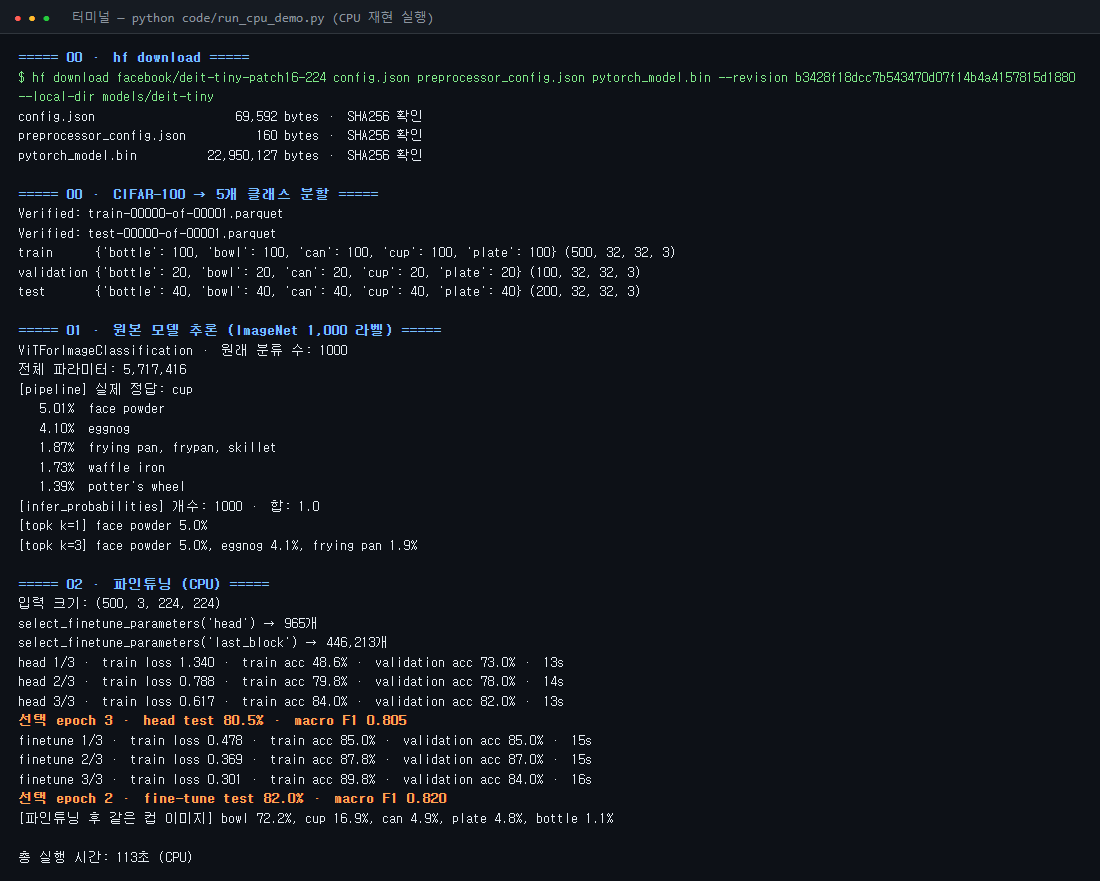

In [5]:
# CPU 재현 실행 터미널 로그
from IPython.display import Image
Image("images/00_terminal_log.png")

### ① 00번: 데이터 확인
클래스마다 학습 이미지 3장씩. 원본이 **32×32**라 많이 흐릿하다. 모델에 넣을 때는 224×224로 키운다.

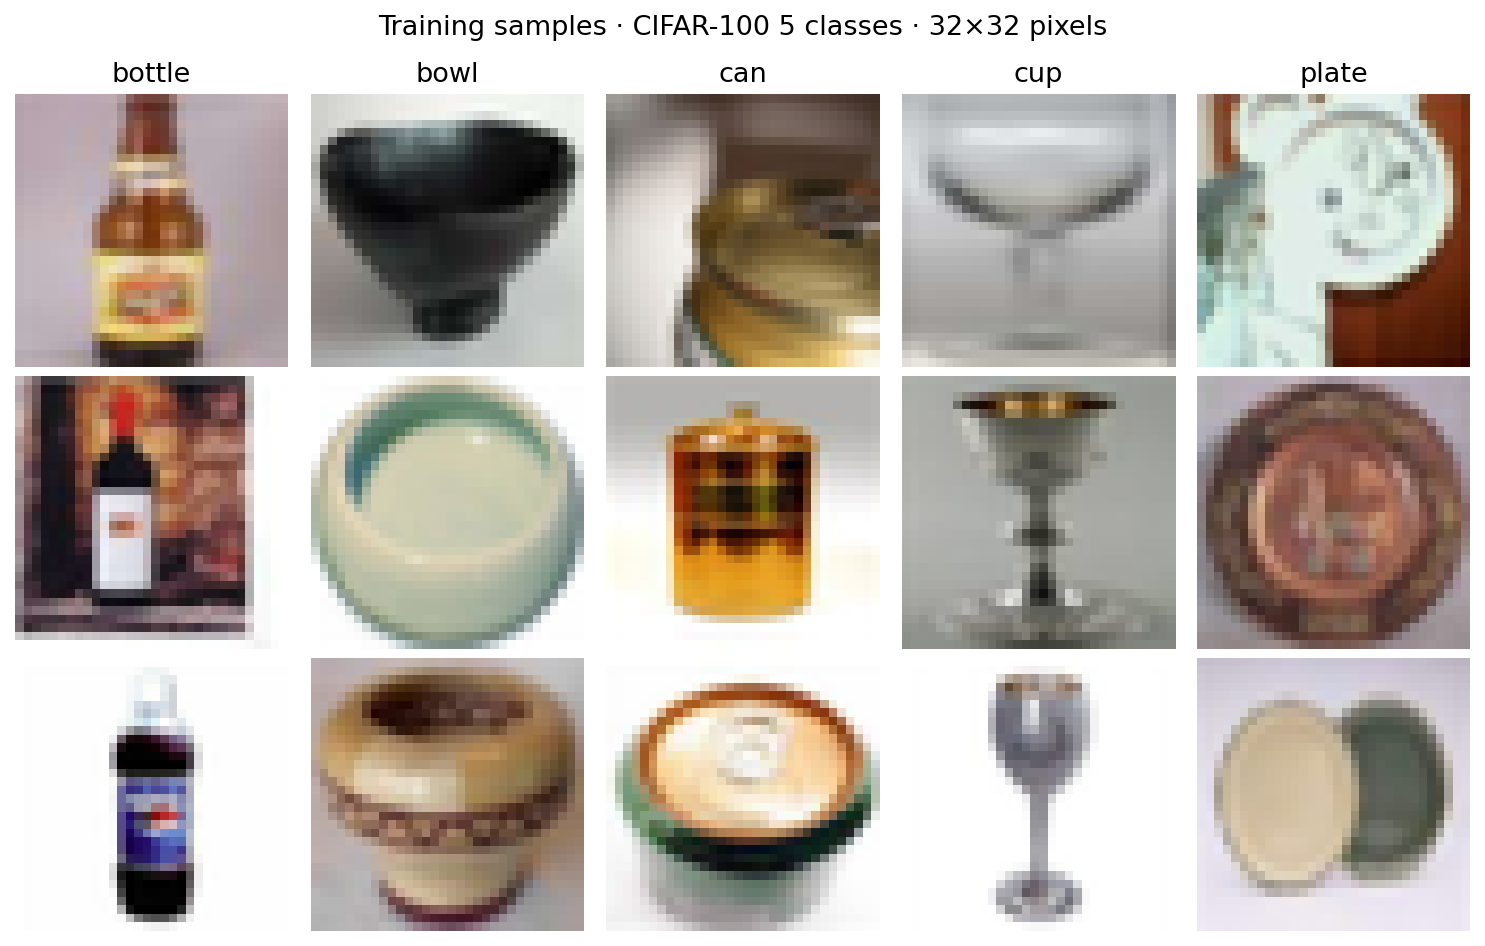

In [6]:
# 학습 데이터 샘플 (5개 클래스 × 3장)
from IPython.display import Image
Image("images/01_data_samples.png")

### ② 01번: 원본 모델은 컵을 모른다
ImageNet 1,000개 라벨로 학습된 원본 모델은 컵 사진을 **face powder 5%** 로 예측했다. 1등 확률조차 5%라서 **확신이 전혀 없는 상태**다. 강의 화면에서 본 결과와 같다.

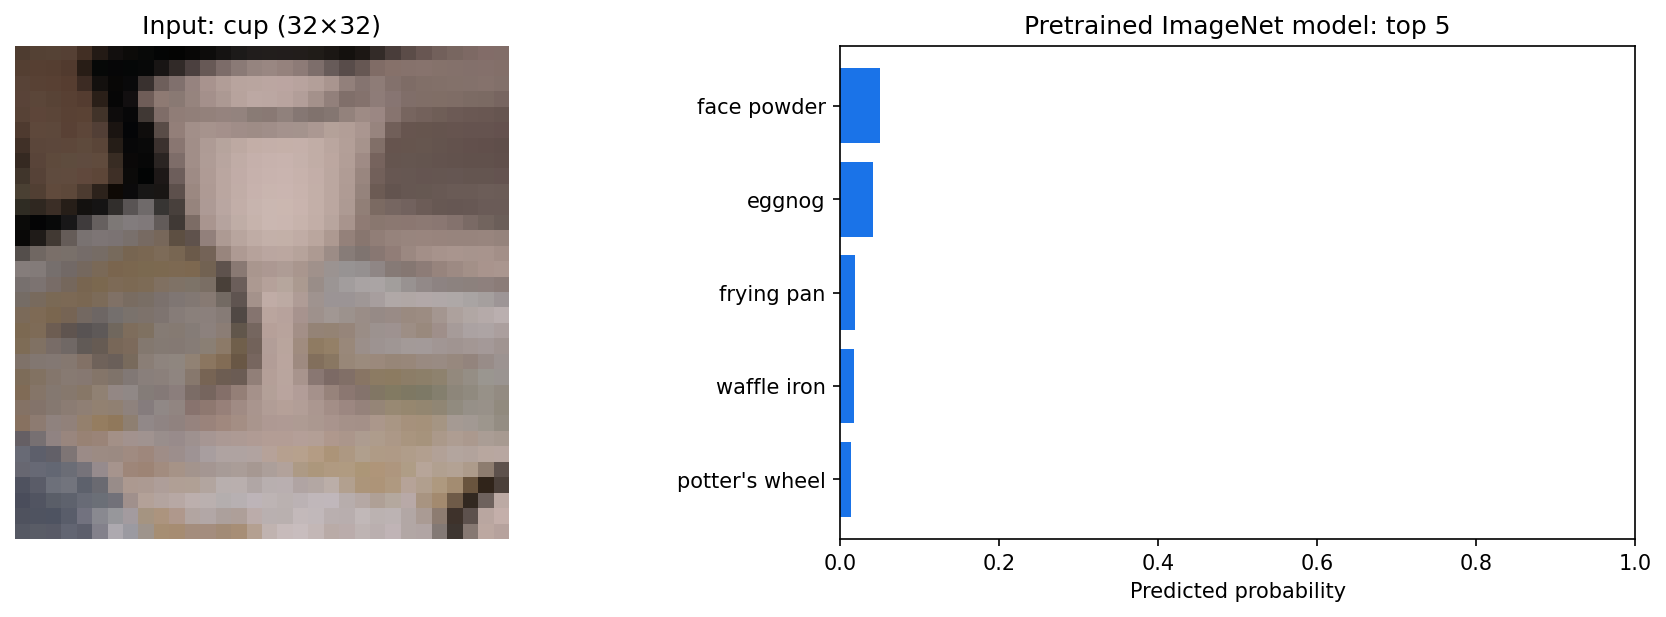

In [7]:
# 원본 모델 Top-5 예측
from IPython.display import Image
Image("images/02_pretrained_top5.png")

### ③ 02번: 학습 곡선
- head(파란색): 3 epoch 동안 손실이 꾸준히 줄고 검증 정확도가 73% → 82%로 오른다.
- finetune(초록색): 검증 정확도가 **2 epoch(87%)에서 최고**이고 3 epoch에는 84%로 떨어진다. 그래서 2 epoch 모델을 골랐다.
- 학습 손실은 계속 줄었지만 검증 손실은 거의 그대로다. **과적합이 시작되는 신호**다.

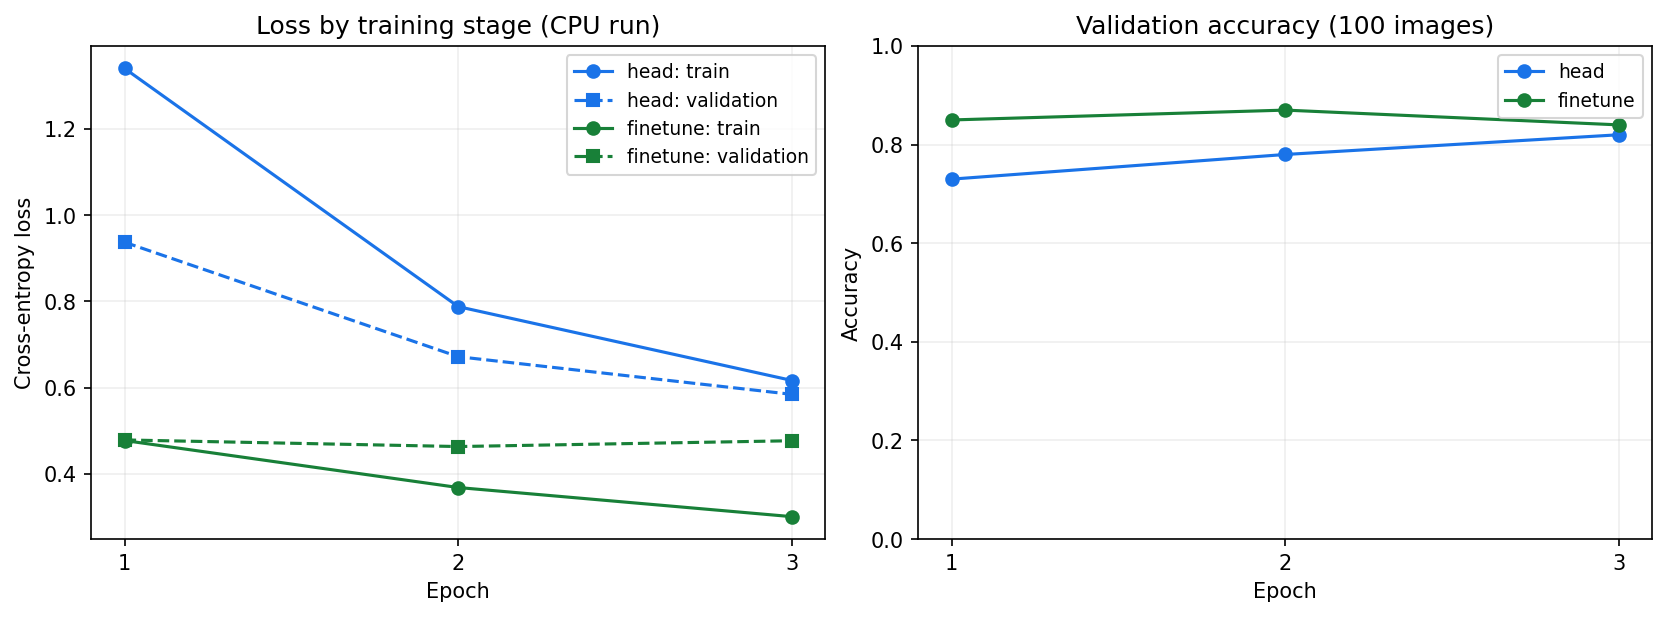

In [8]:
# 단계별 손실과 검증 정확도
from IPython.display import Image
Image("images/03_learning_curves.png")

### ④ 02번: 혼동행렬 비교

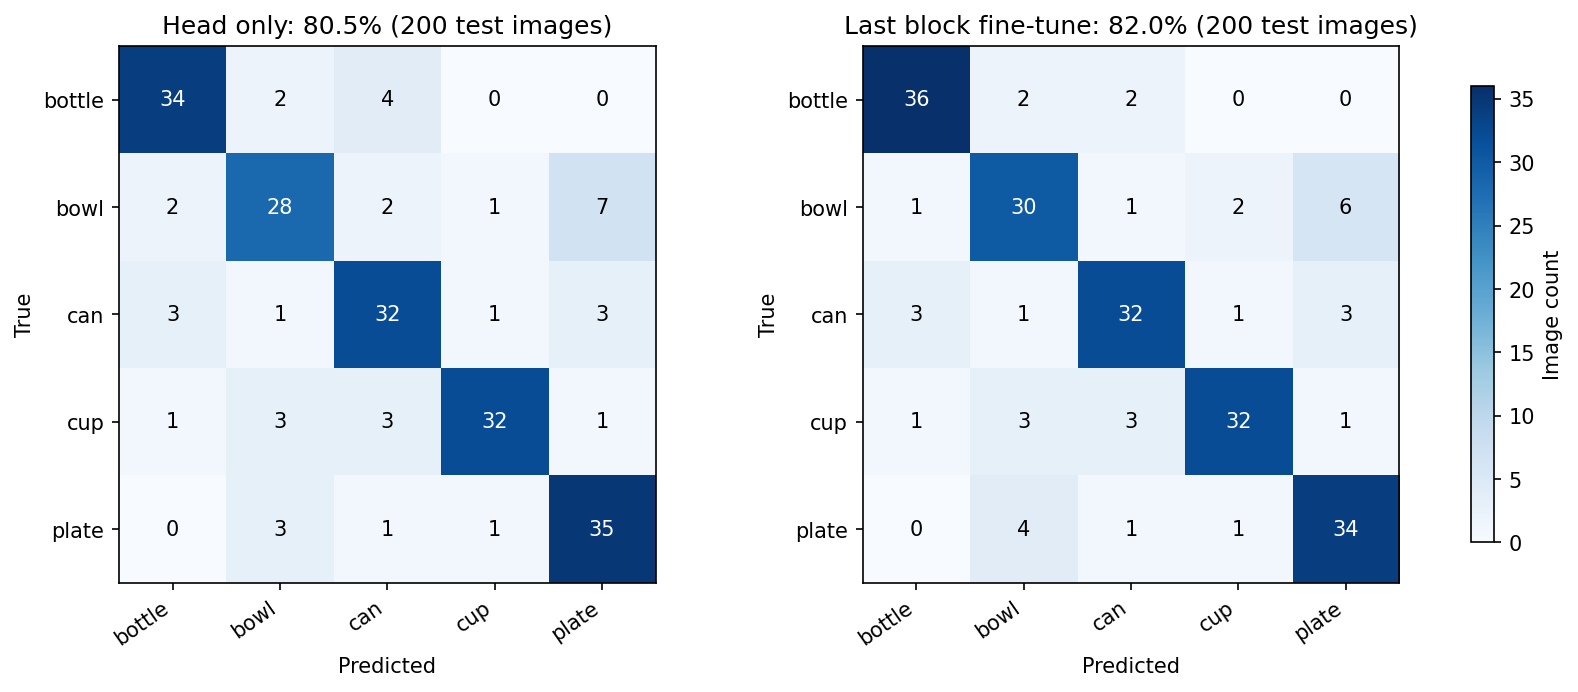

In [9]:
# 테스트 200장 혼동행렬 (head vs fine-tune)
from IPython.display import Image
Image("images/04_confusion_comparison.png")

| 비교 | 내 CPU 재현 (2026-10-03) | 저장소 T4 기록 (2026-09-19) |
|---|---:|---:|
| head only 테스트 정확도 | **80.5%** (F1 0.805) | 80.0% (F1 0.800) |
| last block 파인튜닝 테스트 정확도 | **82.0%** (F1 0.820) | 81.0% (F1 0.809) |
| 파인튜닝 최고 epoch | 2 | 2 |
| 걸린 시간 | 약 2분 (CPU) | (GPU) |

- 가장 많이 틀린 경우는 **bowl을 plate로** 본 것이다 (7장에서 6장). 위에서 찍은 그릇과 접시는 32×32에서 거의 구분이 안 된다.
- 파인튜닝 후 bottle·bowl은 좋아졌지만 plate는 35장에서 34장으로 줄었다. **전체 정확도와 클래스별 변화는 따로 봐야 한다.**
- CPU와 GPU의 숫자가 조금 다른 이유는 연산 장치와 라이브러리 버전 차이 때문이다.

### ⑤ 같은 컵 사진, 파인튜닝 후

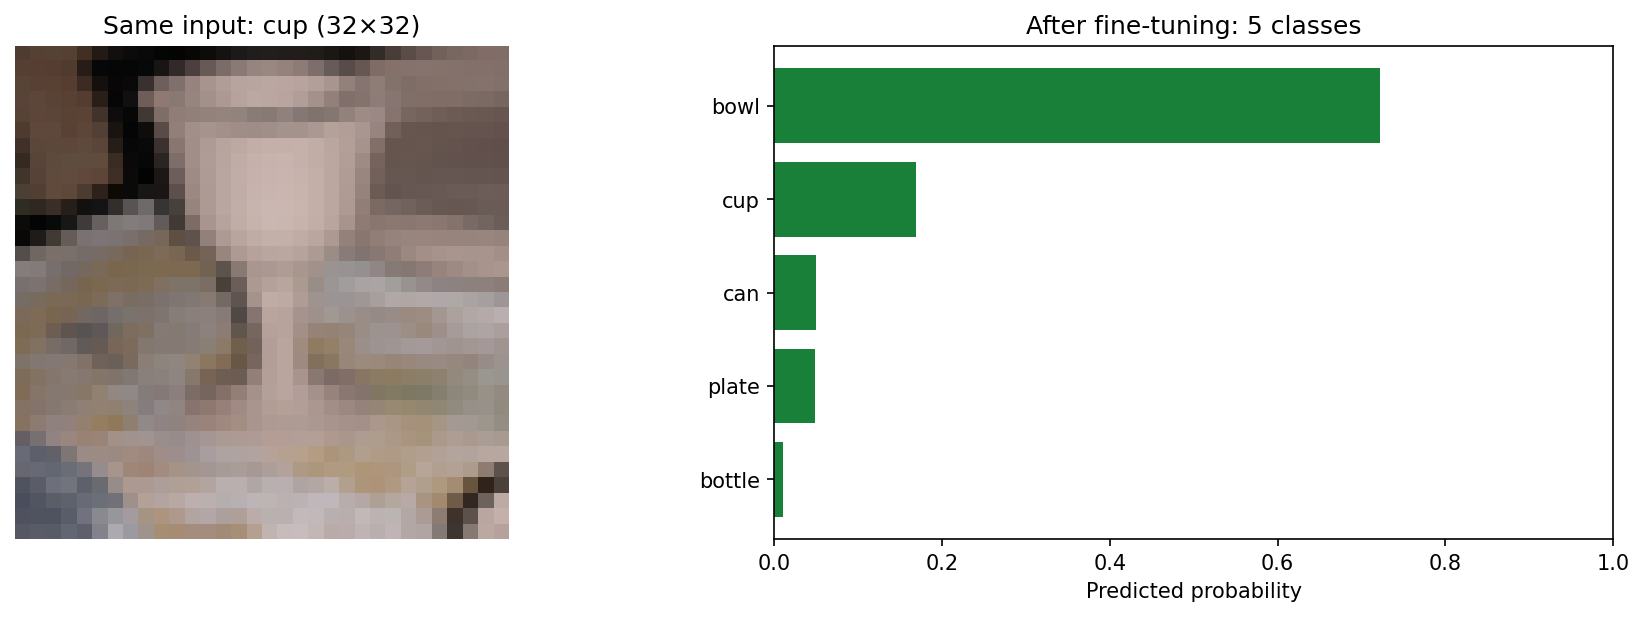

In [10]:
# 파인튜닝 후 같은 컵 이미지 예측
from IPython.display import Image
Image("images/05_finetuned_cup.png")

이제 5개 라벨 안에서 답한다. 하지만 이 사진은 **bowl 72%, cup 17%** 로 틀렸다. 테스트 전체 정확도가 82%라도 개별 사진은 틀릴 수 있다. 위에서 내려다본 흐릿한 컵은 그릇처럼 보인다.

### 💡 실행해 보고 알게 된 것
1. **DeiT-tiny(약 570만 파라미터)는 작아서 CPU로도 2분이면 학습된다.** GPU가 꼭 필요한 건 더 큰 모델이나 더 많은 데이터를 다룰 때다. 그래서 강의에서 "T4로 시작해서 필요할 때 키우라"고 했다.
2. 원본 모델의 Top-5는 **출력 형식을 확인하는 용도**다. 5개 클래스 정확도와 비교하면 안 된다.
3. 검증 정확도로 epoch를 고르는 규칙 덕분에 3 epoch의 과적합 모델 대신 2 epoch 모델이 저장됐다.

## 10. 셸 시연 & 에이전트 스킬

### `.sh` 한 번으로 Colab 추론 전체 자동화
```bash
bash hf_colab_gpu/run_pipeline_colab.sh --dry-run          # 계획만 확인 (GPU 안 씀)
colab --auth oauth2 sessions                                # 첫 로그인
bash hf_colab_gpu/run_pipeline_colab.sh                     # 새 T4 → 설치 → 추론 → JSON 회수 → 종료
bash hf_colab_gpu/run_pipeline_colab.sh --image custom_images/my-cup.png   # 내 사진으로
```
자동 시연은 **성공·실패·중단 모두에서 세션 종료를 시도**한다 → 앞에서 말한 "끄는 걸 깜빡" 위험을 코드로 막은 것.

### 스킬이란?
> **AI 코딩 도구(에이전트)가 읽는 작업 안내서**. 새 프로그램이 아니라 "언제·어떤 명령을·어떻게 확인할지" 적은 문서.

```
스킬(SKILL.md)  →  셸 파일(.sh)  →  Colab CLI  →  Python pipeline()  →  결과 JSON
```
- 위치: `.agents/skills/vision-pipeline-inference/SKILL.md`
- 에이전트에게 "이 이미지 Colab에서 추론해 줘"라고 하면, **에이전트가 알아서 CLI를 불러 실행**한다.
- 강의 마지막 포인트: 터미널 + API + help 문서만 있으면, 비주얼 UI 없이도 에이전트가 도구를 쓸 수 있다. **이게 CLI가 다시 뜨는 이유.**

## 11. GPU 고르는 법 (강의 Q&A)

**Q. 실습/프로젝트에서 어떤 컴퓨팅 자원이 효율적인가요?**

| 단계 | 추천 | 이유 |
|---|---|---|
| 처음 실험 | **T4** | 가볍고 CU 적게 씀. 이번 실습은 T4로 충분 |
| 모델 키우기 | **L4** | T4보다 메모리 큼 → 조금 더 좋은 모델 |
| 본격 실험 | **A100** (80GB급) | 큰 모델, 빠른 학습. 대신 CU 많이 씀 |
| 특수 | **TPU** (v5e-1, v6e-1) | 메모리가 매우 크지만 **JAX 등 전용 라이브러리** 필요, PyTorch 코드 그대로는 어려움 |

- H100·G4 같은 상위 GPU는 **Colab Pro+** 필요.
- 👉 전략: **작게 시작(T4) → 잘 되면 모델 키우기(L4) → 확신이 들면 큰 GPU(A100)**

## 12. 막혔던 점 & 트러블슈팅

| 증상 | 원인 | 해결 |
|---|---|---|
| README가 기호투성이로 보임 | 마크다운 원본 보기 상태 | `Ctrl+Shift+V` / `Ctrl+K V` 미리보기 |
| 01·02 Run All에서 `torch` 에러 | Codespaces엔 GPU용 PyTorch 없음 | `colab exec -f`로 **Colab에서** 실행 |
| `colab login` 명령이 없음 | CLI 0.6.0에는 없음 | `colab --auth oauth2 sessions` |
| 로그인 링크가 안 열림 | 터미널 링크 | `Ctrl + 클릭` → 브라우저에서 계정 선택 → 코드 복사해 터미널에 붙여넣기 |
| PyTorch 설치가 중간에 끊김 | `colab install` 대기시간 짧음 | requirements 업로드 후 `exec --timeout 1800`에서 pip |
| 설치했는데 import 이상 | 이전 버전이 메모리에 남음 | `colab restart-kernel` |
| `upload` 실패 | 상위 폴더 자동 생성 안 됨 | 먼저 `exec`로 `mkdir` |
| 학습 중 끊김 | 타임아웃 짧음 | `--timeout`을 넉넉하게(초 단위) |
| 같은 이름 세션 존재 | 이전 세션이 안 꺼짐 | `colab sessions`로 확인 → `stop` 또는 새 이름 |
| 명령은 끝났는데 결과 이상 | 셀 오류 후에도 계속 실행됨 | `*_output.ipynb`에서 오류 확인 |
| 오류 났다고 세션 반복 생성 | CU 낭비 | **기존 세션 상태부터 확인**, 끝나면 반드시 종료 |

## 13. 강사님 마무리 메시지 & 복습 체크리스트

### 💬 기억할 말
- *"AI 시대에는 코드를 한 줄씩 외우는 것보다, **어떤 개념이고 무엇을 활용하는지**가 중요하다."*
- *"정신없이 따라 하다 보면 머릿속에 남는 게 없다. **흐름을 말이나 글로 정리**해 봐야 한다."*
- *"우리는 같이 프로젝트하는 팀원이다. 막히면 **어떤 작업 중이고 어떤 상태인지** 구체적으로 말해야 도와줄 수 있다."*
- *"다음 단계는 **내 프로젝트에 적용**하기: 다른 모델을 쓰려면 코드의 어디를 바꿔야 하는지 생각해 보자."*

### 🔧 내 프로젝트에 적용할 때 바꿀 곳
| 바꾸고 싶은 것 | 바꿀 위치 |
|---|---|
| 다른 모델 | `MODEL_ID`, `MODEL_REVISION`, `hf download` 대상 |
| 다른 작업 (탐지, OCR 등) | `pipeline("작업이름")`, `AutoModelFor...` 클래스 |
| 다른 라벨 | 데이터 준비(00번)의 클래스 목록, 분류기 출력 수 |
| 더 큰 GPU | `colab new --gpu L4` 또는 `A100` |
| 모델 찾기 | Hugging Face Hub에서 **Transformers 지원** 필터, Roboflow·Ultralytics(YOLO)·Meta 모델 등 |

### ✅ 복습 체크리스트
- [ ] Colab CLI를 쓰는 이유를 한 문장으로 말할 수 있다 → *내 PC 자원이 부족할 때 원격 GPU를 명령어로 빌려 쓰기 위해*
- [ ] Colab 노트북 vs CLI 차이를 설명할 수 있다
- [ ] `new → upload → exec → download → stop → sessions` 순서를 안다
- [ ] revision(커밋 SHA)을 고정하는 이유를 안다
- [ ] 모델 파일 3개(설정·전처리·가중치)의 역할을 안다
- [ ] 01·02를 왜 Codespaces에서 Run All 하면 안 되는지 안다
- [ ] `head`(965) vs `last_block`(446,213) 차이를 안다
- [ ] 마크다운 미리보기 단축키 `Ctrl+Shift+V`를 안다
- [ ] **실습 후 Colab 세션 종료 + Codespace 중지**를 했다 ⭐

### 📚 더 볼 자료 (저장소 안)
- `hf_colab_gpu/README.md` — 단계별 실행 안내
- `hf_colab_gpu/explanations/` — 00·01·02 **코드 해설 노트북** (초보자용, CPU에서 실행 가능)
- `hf_colab_gpu/ai-coding-workshop.md` — 핵심 코드 4개와 조건 바꾸기 실습
- `hf_colab_gpu/pipeline-guide.md` — Pipeline·셸·스킬 안내